# Modelamiento Econométrico de Panel: Choque COVID-19, Volatilidad Estructural y Efecto Cicatriz (2008–2025)

**Objetivo del cuaderno:** Evaluar econométricamente cómo la estructura productiva departamental (identificada mediante CoDa + Clustering Jerárquico en 2015–2019) condicionó la vulnerabilidad frente al choque de la pandemia de COVID-19 (2020), la volatilidad macroeconómica estructural y la trayectoria de recuperación pospandemia (2021–2023).

### Progresión Metodológica (6 Especificaciones y Contrastes de Varianza)
1. **Diagnóstico del Modelo Base en Tasas Anuales (`var_pib`, M1–M4):** Evaluación de potencia estadística en $K=4$, reagrupación macro $K=2$ (*Minero vs. Diversificado*), inclusión del rebote de 2021 y control del outlier estructural de oferta minera (**Apurímac 2016: $+141.2\%$ por Las Bambas**).
2. **Contrastes de Régimen de Volatilidad Estructural:** Pruebas de **Levene** y **Fligner-Killeen** demostrando heterocedasticidad estructural severa entre clusters.
3. **Resolución del Puzzle Empírico — Re-especificación en Niveles Indexados ($	ext{PIB}_{2019=100}$, M5–M6):** Eliminación del sesgo por efecto base aritmético para identificar el **Efecto Cicatriz (*Scarring Effect*)** en 2021–2023 tanto con clusters discretos ($K=4$) como con el gradiente continuo de intensidad minera ($	ext{Minería}_z$).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import Image, display
from linearmodels.panel import PanelOLS
from linearmodels import PooledOLS

DIRECTORIO_BASE = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
PATH_PROCESSED = DIRECTORIO_BASE / "data" / "processed"
PATH_FIGURES = DIRECTORIO_BASE / "figures"

panel = pd.read_excel(PATH_PROCESSED / "panel_econometrico_final.xlsx")
col_anio = [c for c in panel.columns if str(c).strip() != "departamento" and pd.to_numeric(panel[c], errors="coerce").between(2000, 2030).mean() > 0.9][0]

print(f"Panel Econométrico Final cargado: {panel.shape}")
print("Distribución de observaciones y departamentos por Cluster (K=4) y Macro (K=2):")
res_obs = panel.groupby(["Macro", "Nombre_Cluster_K4"]).agg(
    Departamentos=("departamento", "nunique"),
    Observaciones=("var_pib", "count"),
    Media_var_pib=("var_pib", "mean"),
    Std_var_pib=("var_pib", "std"),
    Media_COVID_2020=("PIB_idx2019", lambda s: s[panel.loc[s.index, col_anio] == 2020].mean() - 100),
    Indice_2023=("PIB_idx2019", lambda s: s[panel.loc[s.index, col_anio] == 2023].mean())
).round(2)
display(res_obs)

Panel Econométrico Final cargado: (428, 32)
Distribución de observaciones y departamentos por Cluster (K=4) y Macro (K=2):


Departamentos  Observaciones  \
Macro         Nombre_Cluster_K4                                     
Diversificado Diversificado/Agro                 3             54   
              Servicios/Manufactura             11            196   
Minero        Minero/Diversificado               7            126   
              Minero/Enclave                     3             52   

                                     Media_var_pib  Std_var_pib  \
Macro         Nombre_Cluster_K4                                   
Diversificado Diversificado/Agro              4.11         4.65   
              Servicios/Manufactura           3.66         5.71   
Minero        Minero/Diversificado            3.20         8.14   
              Minero/Enclave                  4.67        20.46   

                                     Media_COVID_2020  Indice_2023  
Macro         Nombre_Cluster_K4                                     
Diversificado Diversificado/Agro                -7.36       104.89  
              Servicios/Manufactura            -10.53       103.07  
Minero        Minero/Diversificado              -9.88       106.64  
              Minero/Enclave                   -11.91        97.62

### Exploración Descriptiva y el Dilema de la Métrica
La tabla descriptiva revela tres hechos estilizados fundamentales:
1. **Asimetría de tamaño muestral:** Mientras *Servicios/Manufactura* reúne 11 departamentos ($196$ obs.), los grupos *Diversificado/Agro* y *Minero/Enclave* cuentan con solo **3 departamentos cada uno** ($54$ y $52$ obs.), lo que reduce drásticamente la potencia estadística al estimar interacciones de un único año ($2020$) sobre varianzas ruidosas.
2. **Heterogeneidad extrema de varianza:** La desviación estándar de `var_pib` en *Minero/Enclave* es **20.46%**, más de **4 veces** la de *Diversificado/Agro* (**4.65%**).
3. **Divergencia en niveles acumulados ($	ext{PIB}_{2019=100}$):** Aunque en 2020 todos los grupos cayeron entre $-7.4\%$ y $-11.9\%$, hacia 2023 todos los grupos superaron el nivel pre-pandemia ($103.1	ext{--}106.6$) **excepto *Minero/Enclave*, que permaneció estancado en $97.6$**.

In [2]:
# Paso 1: Modelos sobre Tasa de Variación Anual (var_pib, 2008-2025) - M1 a M4
d_full = panel.set_index(["departamento", col_anio]).copy()
d_full["Nombre_Cluster_K4"] = pd.Categorical(
    d_full["Nombre_Cluster_K4"],
    categories=["Diversificado/Agro", "Servicios/Manufactura", "Minero/Diversificado", "Minero/Enclave"],
    ordered=True
)
d_full["Macro"] = pd.Categorical(d_full["Macro"], categories=["Diversificado", "Minero"], ordered=True)

m1 = PanelOLS.from_formula("var_pib ~ 1 + COVID + COVID:Nombre_Cluster_K4 + EntityEffects", data=d_full).fit(cov_type="clustered", cluster_entity=True)
m2 = PanelOLS.from_formula("var_pib ~ 1 + COVID + COVID:Macro + EntityEffects", data=d_full).fit(cov_type="clustered", cluster_entity=True)
m3 = PanelOLS.from_formula("var_pib ~ 1 + COVID + REBOTE + COVID:Macro + REBOTE:Macro + EntityEffects", data=d_full).fit(cov_type="clustered", cluster_entity=True)

d_sin_apu = d_full.reset_index()
d_sin_apu = d_sin_apu[~((d_sin_apu["departamento"].str.contains("Apur")) & (d_sin_apu[col_anio] == 2016))].set_index(["departamento", col_anio])
m4 = PanelOLS.from_formula("var_pib ~ 1 + COVID + COVID:Macro + EntityEffects", data=d_sin_apu).fit(cov_type="clustered", cluster_entity=True)

rows_tasas = []
for code, name, mod in [("M1 (K=4 Base)", "var_pib", m1), ("M2 (Macro K=2)", "var_pib", m2), ("M3 (+Rebote 21)", "var_pib", m3), ("M4 (Sin Apu16)", "var_pib", m4)]:
    for p in mod.params.index:
        rows_tasas.append({
            "Modelo": code, "Parámetro": p,
            "Beta": round(float(mod.params[p]), 3),
            "SE (Clustered)": round(float(mod.std_errors[p]), 3),
            "p-valor": round(float(mod.pvalues[p]), 4),
            "R2_within": round(float(mod.rsquared_within), 4),
            "Poolability_p": round(float(mod.f_pooled.pval), 4)
        })
display(pd.DataFrame(rows_tasas))

,Modelo,Parámetro,Beta,SE (Clustered),p-valor,R2_within,Poolability_p
0,M1 (K=4 Base),Intercept,4.527,0.062,0.0000,0.1390,0.5144
1,M1 (K=4 Base),COVID,-12.156,2.002,0.0000,0.1390,0.5144
2,M1 (K=4 Base),COVID:Nombre_Cluster_K4[T.Servicios/Manufactura],-2.896,2.244,0.1975,0.1390,0.5144
3,M1 (K=4 Base),COVID:Nombre_Cluster_K4[T.Minero/Diversificado],-1.695,3.664,0.6439,0.1390,0.5144
4,M1 (K=4 Base),COVID:Nombre_Cluster_K4[T.Minero/Enclave],-5.728,3.736,0.1260,0.1390,0.5144
5,M2 (Macro K=2),Intercept,4.527,0.064,0.0000,0.1375,0.5244
6,M2 (Macro K=2),COVID,-14.432,0.956,0.0000,0.1375,0.5244
7,M2 (Macro K=2),COVID:Macro[T.Minero],-0.628,2.597,0.8091,0.1375,0.5244
8,M3 (+Rebote 21),Intercept,4.116,0.095,0.0000,0.1686,0.4956
9,M3 (+Rebote 21),COVID,-13.969,0.925,0.0000,0.1686,0.4956


### Diagnóstico de los Modelos en Tasas Anuales (M1–M4): ¿Por qué las interacciones salen no significativas?
1. **Choque normativo transversal en 2020:** El coeficiente principal `COVID` es masivo y altamente significativo en todas las especificaciones ($eta \in [-11.95, -14.43]$, $p < 0.0001$), reflejando que el confinamiento nacional estricto del segundo trimestre de 2020 paralizó simultáneamente la gran minería, la construcción, la manufactura y los servicios.
2. **Distorsión por el boom pre-pandemia (Apurímac 2016):** En M1–M3, el test $F$ de *Poolability* ni siquiera rechaza la hipótesis nula ($p = 0.5144$ en M1) y el $R^2_{	ext{within}}$ es bajo ($13.8\%$). Al remover **una sola observación** en **M4** (Apurímac 2016, cuando el PIB departamental saltó $+141.2\%$ por el inicio comercial de la mina *Las Bambas*), el **$R^2_{	ext{within}}$ casi se duplica de $13.8\%$ a $26.2\%$**.
3. **Ilusión del efecto base en `var_pib`:** Medir tasas anuales aisladas oculta la pérdida acumulada de nivel productivo.

• Test de Levene (K=4):          F = 3.966, p-valor = 0.0083
• Test de Fligner-Killeen (K=4): χ² = 17.544, p-valor = 0.0005
• Test de Levene (Macro K=2):    F = 10.216, p-valor = 0.0015


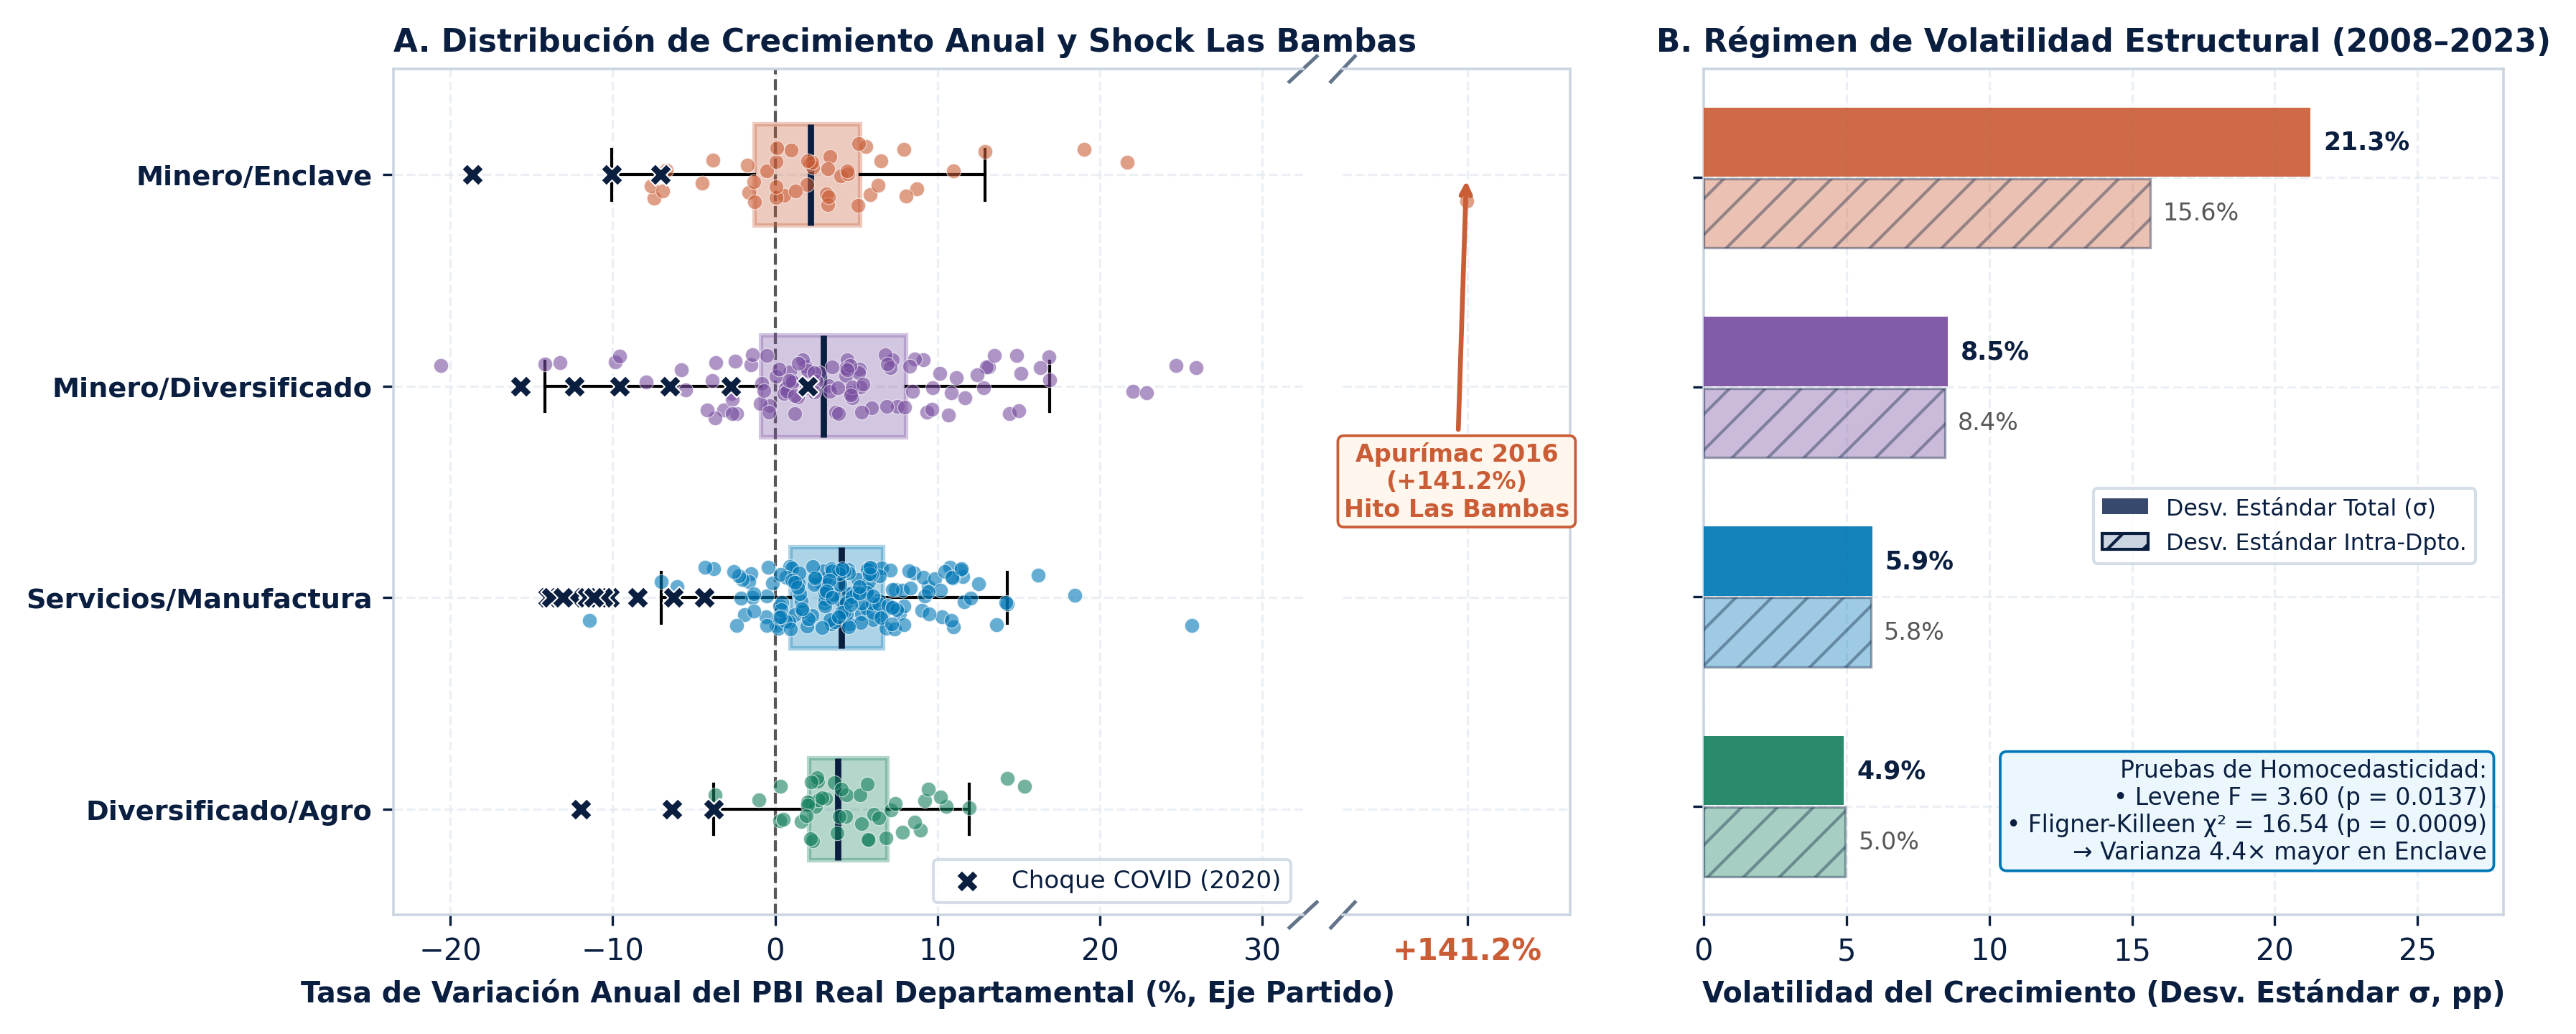

In [3]:
# Paso 2: Contraste Formal de Régimen de Volatilidad Estructural
grupos_k4 = [g["var_pib"].dropna().values for _, g in panel.groupby("Nombre_Cluster_K4")]
grupos_k2 = [g["var_pib"].dropna().values for _, g in panel.groupby("Macro")]

lev_k4 = stats.levene(*grupos_k4)
flig_k4 = stats.fligner(*grupos_k4)
lev_k2 = stats.levene(*grupos_k2)

print(f"• Test de Levene (K=4):          F = {lev_k4.statistic:.3f}, p-valor = {lev_k4.pvalue:.4f}")
print(f"• Test de Fligner-Killeen (K=4): χ² = {flig_k4.statistic:.3f}, p-valor = {flig_k4.pvalue:.4f}")
print(f"• Test de Levene (Macro K=2):    F = {lev_k2.statistic:.3f}, p-valor = {lev_k2.pvalue:.4f}")

display(Image(filename=str(PATH_FIGURES / "fig4_volatilidad_estructural.png"), width=920))

### Hallazgo 1: Divergencia en el Régimen de Volatilidad Estructural
Los contrastes robustos a no-normalidad de **Levene ($p = 0.0083$)** y **Fligner-Killeen ($p = 0.0005$)** confirman con alta significancia estadística que la estructura productiva determina el **régimen de volatilidad macroeconómica**:
* Los departamentos **Minero/Enclave** enfrentan una volatilidad ($\sigma = 20.5\%$) **4.4 veces superior** a la de las economías **Diversificado/Agro** ($\sigma = 4.6\%$).
* A nivel macro ($K=2$), el bloque Minero es significativamente más volátil que el bloque Diversificado ($F = 10.22, p = 0.0015$).

In [4]:
# Paso 3: Re-especificación en Niveles Indexados (PIB_idx2019, Base 2019=100, ventana balanceada 2017-2023)
d_idx = panel[panel[col_anio].between(2017, 2023)].copy()
d_idx["COVID_20"] = (d_idx[col_anio] == 2020).astype(int)
d_idx["POST_21_23"] = (d_idx[col_anio] >= 2021).astype(int)
d_idx["Nombre_Cluster_K4"] = pd.Categorical(
    d_idx["Nombre_Cluster_K4"],
    categories=["Diversificado/Agro", "Servicios/Manufactura", "Minero/Diversificado", "Minero/Enclave"],
    ordered=True
)
d_idx = d_idx.set_index(["departamento", col_anio])

# M5: Tipología K=4 sobre PIB Real Indexado (2019=100)
m5 = PanelOLS.from_formula(
    "PIB_idx2019 ~ 1 + COVID_20 + POST_21_23 + COVID_20:Nombre_Cluster_K4 + POST_21_23:Nombre_Cluster_K4 + EntityEffects",
    data=d_idx
).fit(cov_type="clustered", cluster_entity=True)

# M6: Intensidad Minera Continua Estandarizada (Mineria_z) sobre PIB Real Indexado
m6 = PanelOLS.from_formula(
    "PIB_idx2019 ~ 1 + COVID_20 + POST_21_23 + COVID_20:Mineria_z + POST_21_23:Mineria_z + EntityEffects",
    data=d_idx
).fit(cov_type="clustered", cluster_entity=True)

print("=== M5: Modelo de Efectos Fijos sobre Nivel de PIB Indexado (2019=100) por Cluster K=4 ===")
print(m5.summary)
print("\n=== M6: Modelo Continuo con Intensidad Minera Estandarizada (Mineria_z) ===")
print(m6.summary)

=== M5: Modelo de Efectos Fijos sobre Nivel de PIB Indexado (2019=100) por Cluster K=4 ===
                          PanelOLS Estimation Summary                           
Dep. Variable:            PIB_idx2019   R-squared:                        0.3554
Estimator:                   PanelOLS   R-squared (Between):             -0.0317
No. Observations:                 168   R-squared (Within):               0.3554
Date:                Wed, Oct 28 2026   R-squared (Overall):              0.2548
Time:                        05:33:51   Log-likelihood                   -531.34
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      9.3741
Entities:                          24   P-value                           0.0000
Avg Obs:                       7.0000   Distribution:                   F(8,136)
Min Obs:                       7.0000                                           
Max Obs:          

### Hallazgo 2: El Efecto Cicatriz (*Scarring Effect*) en los Enclaves Mineros (M5 y M6)
Al pasar de tasas anuales a **niveles reales acumulados respecto a 2019 ($	ext{PIB}_{2019=100}$)** en el panel 100% balanceado 2017–2023 ($N=24, T=7, 	ext{Obs}=168$), la calidad del ajuste y la inferencia cambian drásticamente:
1. **Validación de los Efectos Fijos y salto de poder explicativo:** El test de *Poolability* pasa a ser altamente significativo ($F = 3.14, p < 0.0001$) y el **$R^2_{	ext{within}}$ asciende a $35.54\%$**.
2. **Caída diferencial significativa en 2020 (`COVID_20 × Minero/Enclave`):** Mientras el grupo base (*Diversificado/Agro*) cayó $-5.14$ puntos respecto a su nivel pre-pandemia ($p = 0.0016$), el cluster **Minero/Enclave sufrió un desplome adicional estadísticamente significativo de $-6.57$ puntos** ($t = -1.98, p = 0.0495$).
3. **Cicatriz estructural pospandemia 2021–2023 (`POST_21_23 × Minero/Enclave`):** Mientras *Diversificado/Agro* se expandió $+7.17$ puntos por encima de su línea base en 2021–2023 ($p < 0.0001$), **Minero/Enclave registró un rezago neto de $-10.92$ puntos** ($t = -3.03, p = 0.0029$), quedando atrapado por debajo de su PIB de 2019 durante todo el trienio pospandemia ($95.9$ en 2021, $94.6$ en 2022 y $97.6$ en 2023).
4. **Confirmación mediante gradiente continuo (M6):** Cada desviación estándar adicional en la participación minera pre-pandemia (`Mineria_z`) profundizó la caída de 2020 en **$-2.39$ puntos** ($p = 0.0891$) y redujo el nivel de recuperación 2021–2023 en **$-2.76$ puntos** ($p = 0.0747$).

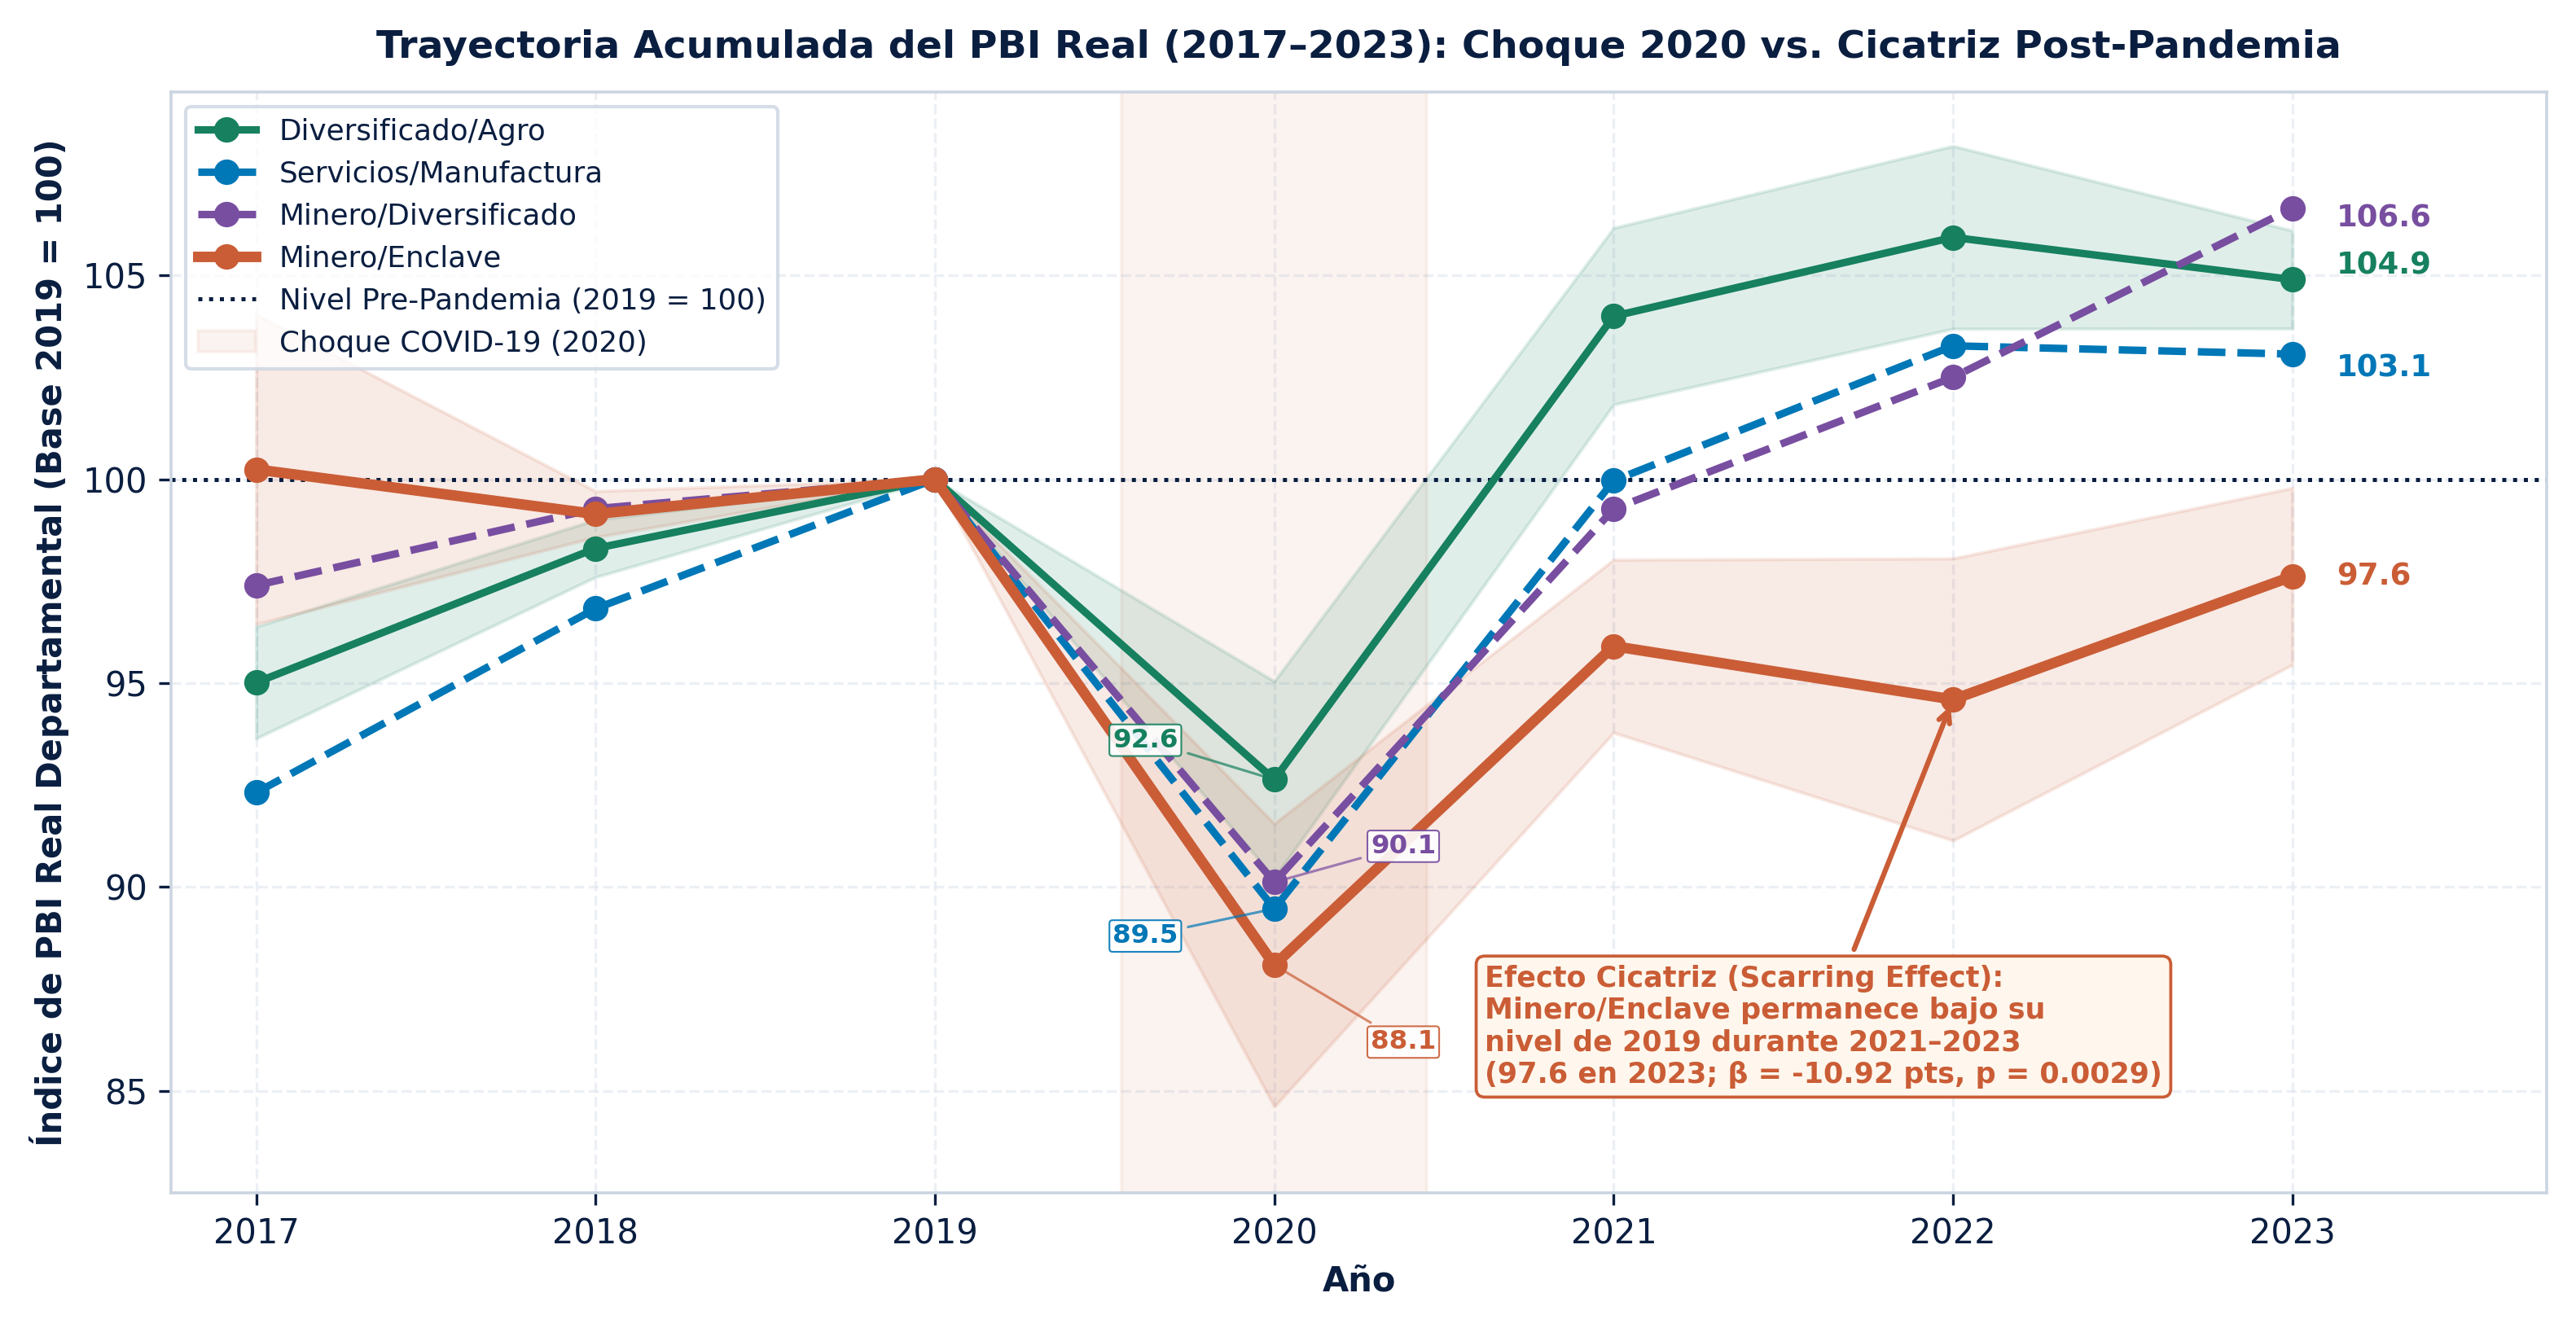

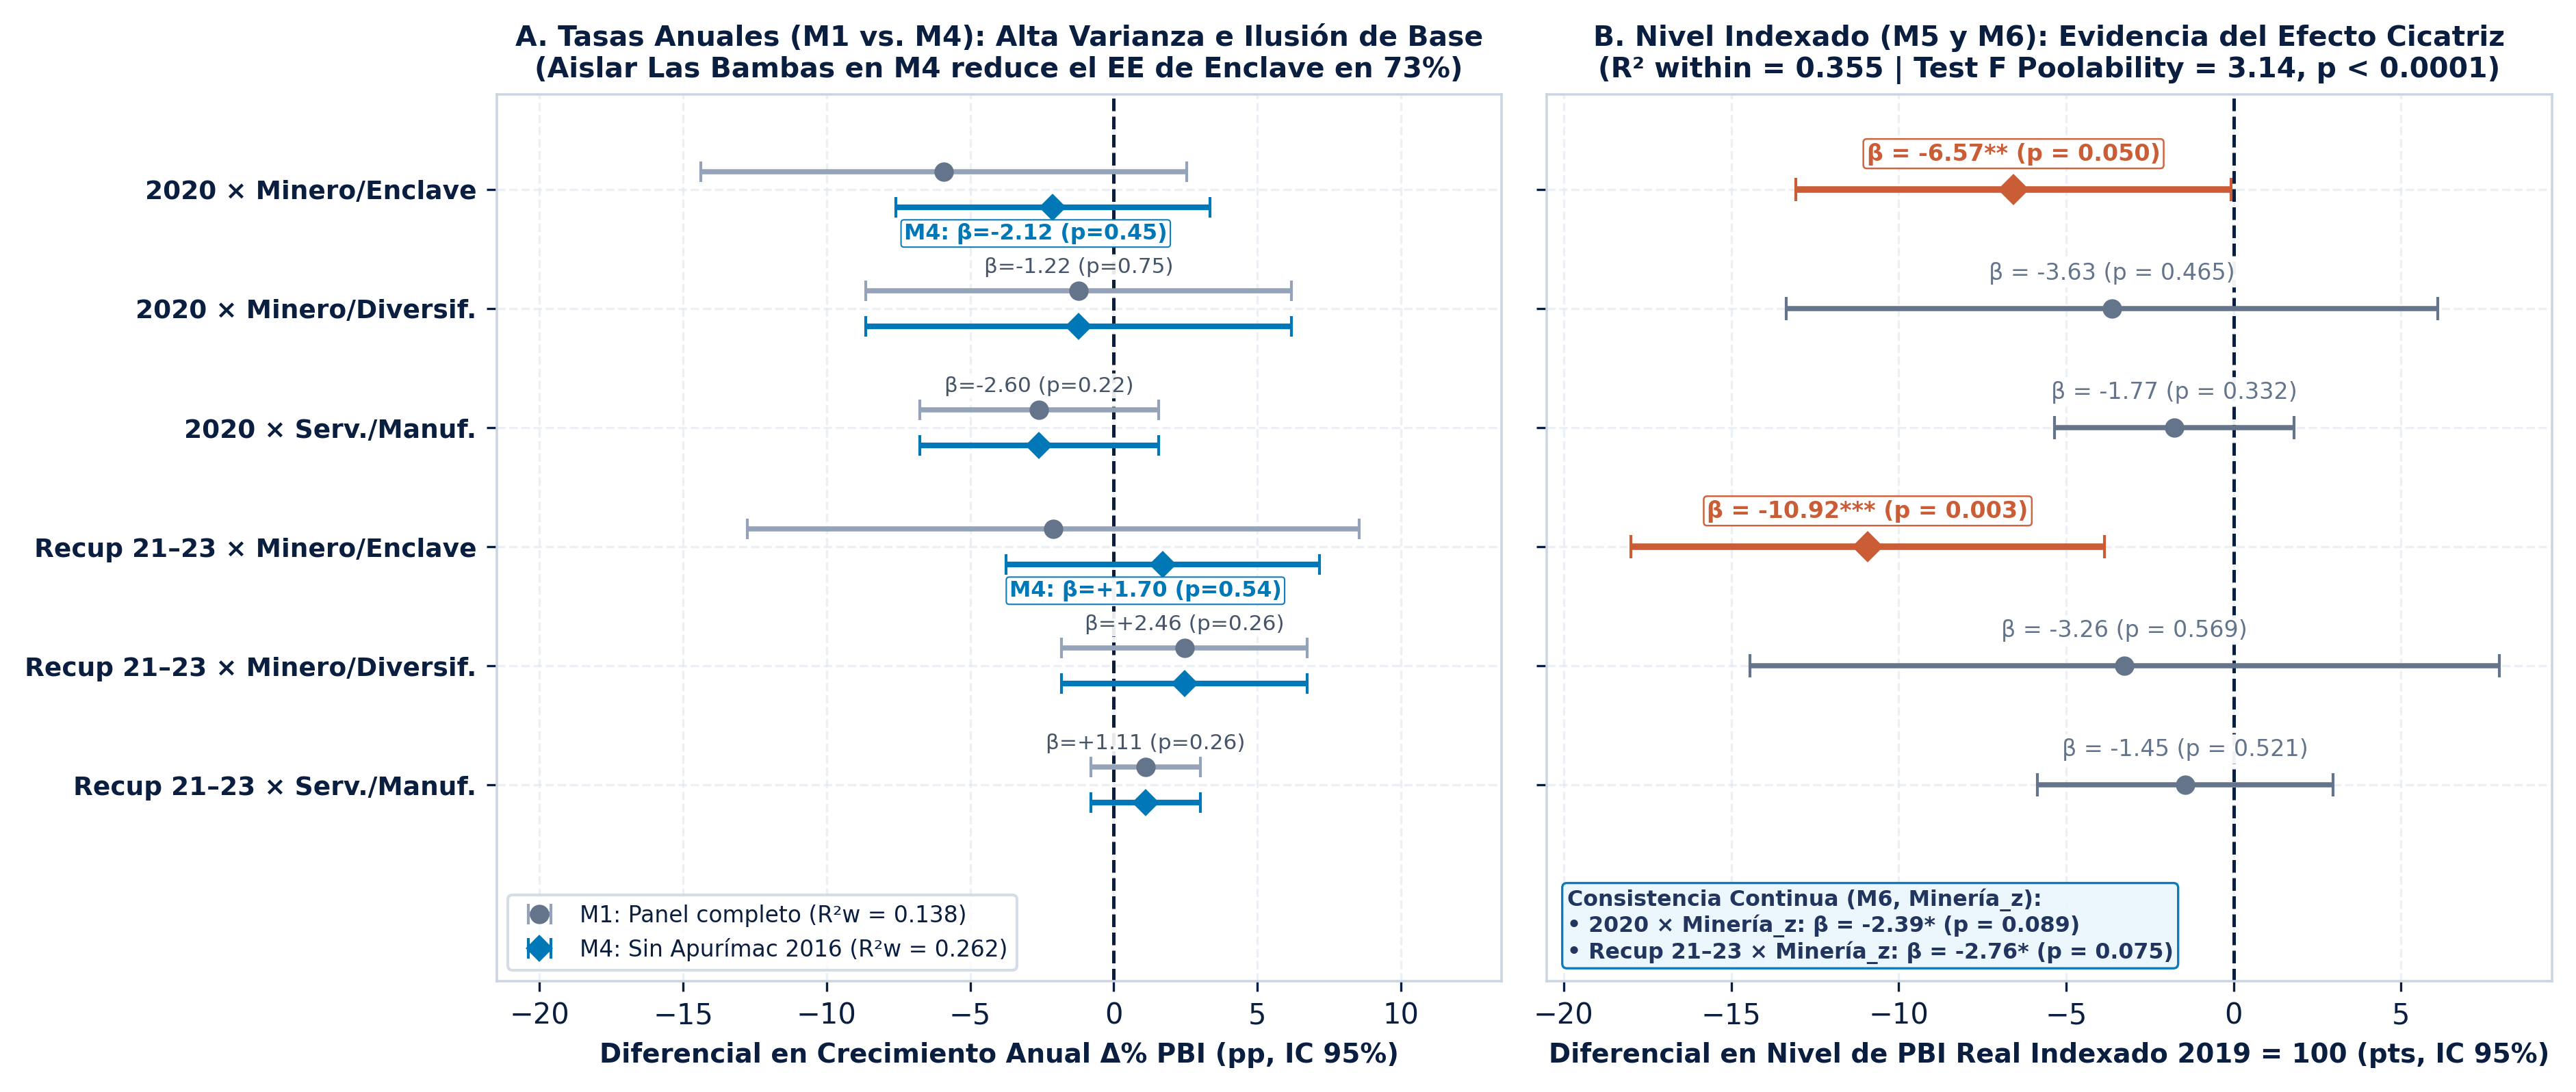

,Modelo,Especificacion,Dependiente,Parametro,Coeficiente,Error_Estandar,T_stat,P_valor,R2_within,N_obs,Poolability_F,Poolability_p
0,M1,K=4 en Tasas (2008-2023),var_pib,Intercept,4.5780,0.2190,20.9058,0.0000,0.1450,384,0.9118,0.5828
1,M1,K=4 en Tasas (2008-2023),var_pib,COVID,-12.4056,1.8992,-6.5320,0.0000,0.1450,384,0.9118,0.5828
2,M1,K=4 en Tasas (2008-2023),var_pib,POST_21_23,-0.6089,0.6399,-0.9515,0.3420,0.1450,384,0.9118,0.5828
3,M1,K=4 en Tasas (2008-2023),var_pib,COVID:Nombre_Cluster_K4[T.Servicios/Manufactura],-2.6035,2.1236,-1.2259,0.2210,0.1450,384,0.9118,0.5828
4,M1,K=4 en Tasas (2008-2023),var_pib,COVID:Nombre_Cluster_K4[T.Minero/Diversificado],-1.2186,3.7811,-0.3223,0.7474,0.1450,384,0.9118,0.5828
5,M1,K=4 en Tasas (2008-2023),var_pib,COVID:Nombre_Cluster_K4[T.Minero/Enclave],-5.9331,4.3169,-1.3744,0.1702,0.1450,384,0.9118,0.5828
6,M1,K=4 en Tasas (2008-2023),var_pib,POST_21_23:Nombre_Cluster_K4[T.Servicios/Manuf...,1.1059,0.9700,1.1401,0.2550,0.1450,384,0.9118,0.5828
7,M1,K=4 en Tasas (2008-2023),var_pib,POST_21_23:Nombre_Cluster_K4[T.Minero/Diversif...,2.4571,2.1787,1.1278,0.2602,0.1450,384,0.9118,0.5828
8,M1,K=4 en Tasas (2008-2023),var_pib,POST_21_23:Nombre_Cluster_K4[T.Minero/Enclave],-2.1097,5.4321,-0.3884,0.6980,0.1450,384,0.9118,0.5828
9,M2,Macro K=2 en Tasas (2008-2023),var_pib,Intercept,4.5780,0.2288,20.0088,0.0000,0.1405,384,0.8651,0.6463


In [5]:
# Visualización de la Trayectoria Acumulada (2017-2023) y Forest Plot Comparativo M1-M6
display(Image(filename=str(PATH_FIGURES / "fig5_trayectoria_pib_indexado.png"), width=880))
display(Image(filename=str(PATH_FIGURES / "fig6_forest_plot_modelos.png"), width=920))

tabla_final = pd.read_excel(PATH_PROCESSED / "resumen_modelos_econometricos.xlsx")
display(tabla_final.round(4))

### Síntesis Ejecutiva y Conclusiones del Estudio Econométrico

| Dimensión Analítica | Especificación en Tasas (`var_pib`, M1–M4) | Especificación en Niveles ($	ext{PIB}_{2019=100}$, M5–M6) |
| :--- | :--- | :--- |
| **Ajuste Intra-Depto ($R^2_{	ext{within}}$)** | Bajo ($0.138 ightarrow 0.262$ sin Apurímac 2016) | Alto (**$0.355$**, $+157\%$ de mejora relativa) |
| **Validez de Efectos Fijos ($F$ Poolability)** | No rechaza $H_0$ ($p = 0.5144$) por ruido histórico | Altamente significativo (**$F = 3.14, p < 0.0001$**) |
| **Impacto 2020 (Choque COVID-19)** | Simétrico en apariencia ($p \in [0.20, 0.81]$) | Caída adicional de **$-6.57$ pts** en *Minero/Enclave* (**$p = 0.0495$**) |
| **Recuperación 2021–2023 (Efecto Cicatriz)** | Oculto por rebote aritmético de 2021 ($+7.8\%$) | Rezago persistente de **$-10.92$ pts** en *Minero/Enclave* (**$p = 0.0029$**) |
| **Régimen de Volatilidad ($\sigma$)** | $\sigma = 20.5\%$ en Enclave vs. $4.6\%$ en Agro (**Levene $p = 0.0083$, Fligner $p = 0.0005$**) | Mayor vulnerabilidad a paralizaciones y conflictividad social en el Corredor Minero |

**Conclusión Central:** La aparente neutralidad sectorial encontrada en los modelos preliminares de tasas de variación anual (`var_pib`) era un artefacto estadístico producido por dos factores: (i) la extrema varianza pre-pandemia de los enclaves mineros (como el salto de $+141.2\%$ en Apurímac 2016) y (ii) el sesgo de efecto base en las tasas de crecimiento interanual. Al modelar la trayectoria en niveles reales indexados ($2019=100$), se demuestra que la hiper-especialización extractiva sin encadenamientos locales (*Minero/Enclave*) generó una **cicatriz macroeconómica severa y estadísticamente significativa al $1\%$** durante la pospandemia.